# v1.LPT_Seasonality_v3 — seasonality of the 1993-2013 Amazon LPT climatology

Plots in the style of `Analysis/LPT_Seasonality.ipynb` (4x3 grid of
`np.log10(counts).plot.contourf(..., cmap='Spectral_r')` with one shared
horizontal colorbar labelled `log10(counts)`), built from the combined
four-seed products written by `v1.All_tracks_v3.ipynb`
(`_hist_month_v3.nc`, `_hist_season_v3.nc`, `_hist_year_month_v3.nc`,
`_hist_age_month_v3.nc`).

* The grid is the **shared** `run_2/analysis` grid (`v2.bins_v3.npz`): linspace
  bin edges from the data extremes, 79 x 29 cells of about 1 deg.
* Maps are drawn over the **full data extent** (about 97W-15W, 4S-32N, out to
  the African coast) — not clipped to the western tropical Atlantic.
* Colour scale is always plain `log10(counts)`; the normalised
  `100*log10(n)/log10(n_max)` (Coles et al. 2013) panels have been dropped.

All figures are written to `figures/` (the `v2.*` PNGs there come from the
monthly-mean notebooks).

In [1]:
# ---- papermill parameters -------------------------------------------------
analysis_dir = "/work/bk1450/b383184/Amazon/Mercator/notebooks/run_2/analysis"
fig_dir      = "/work/bk1450/b383184/Amazon/Mercator/notebooks/run_2/analysis/figures"

in_month      = "_hist_month_v3.nc"
in_season     = "_hist_season_v3.nc"
in_year_month = "_hist_year_month_v3.nc"
in_age        = "_hist_age_month_v3.nc"

fig_dpi = 300
# map extent of the plots (lon_min, lon_max, lat_min, lat_max).
# None -> the full extent of the data / of the bin edges (about 97W-15W, 4S-32N),
# which is what we want: the plume reaches the African coast.
extent = None

In [2]:
import os
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cf
from cartopy.mpl.ticker import LongitudeFormatter, LatitudeFormatter

os.makedirs(fig_dir, exist_ok=True)
proj = ccrs.PlateCarree()
labs = ['JAN','FEB','MAR','APR','MAY','JUN','JUL','AUG','SEP','OCT','NOV','DEC']

hist_month  = xr.open_dataset(os.path.join(analysis_dir, in_month)).compute().histogram_lon_lat
hist_season = xr.open_dataset(os.path.join(analysis_dir, in_season)).compute().histogram_lon_lat
age_month   = xr.open_dataset(os.path.join(analysis_dir, in_age),
                              decode_timedelta=False).compute()
hist_ym     = xr.open_dataset(os.path.join(analysis_dir, in_year_month)).compute().histogram_lon_lat

# full data extent from the bin centres (+/- half a cell = the outer bin edges)
if extent is None:
    _dlon = float(np.diff(hist_month.lon.values).mean())
    _dlat = float(np.diff(hist_month.lat.values).mean())
    extent = [float(hist_month.lon.min()) - _dlon/2, float(hist_month.lon.max()) + _dlon/2,
              float(hist_month.lat.min()) - _dlat/2, float(hist_month.lat.max()) + _dlat/2]
print("grid        :", hist_month.sizes["lon"], "x", hist_month.sizes["lat"], "cells,",
      f"{float(np.diff(hist_month.lon.values).mean()):.3f} x "
      f"{float(np.diff(hist_month.lat.values).mean()):.3f} deg")
print("map extent  :", [round(e, 2) for e in extent])
print("total positions in the monthly histogram :", f"{int(hist_month.sum()):,}")
print("release years covered                    :", hist_ym.start_year.values.min(),
      "-", hist_ym.start_year.values.max())
_a = xr.open_dataset(os.path.join(analysis_dir, in_month)).attrs
print("stores / trajectories behind it          :",
      _a.get("n_stores"), "/", _a.get("n_trajectories"))
hist_month

grid        : 79 x 29 cells, 1.041 x 1.255 deg
map extent  : [-96.94, -14.67, -4.38, 32.02]
total positions in the monthly histogram : 11,148,916,375
release years covered                    : 1993 - 2013
stores / trajectories behind it          : 1534 / 15485167


<xarray.DataArray 'histogram_lon_lat' (start_month: 12, obs: 36, lon: 79,
                                       lat: 29)> Size: 8MB
array([[[[ 0,  0,  0, ...,  0,  0,  0],
         [ 0,  0,  0, ...,  0,  0,  0],
         [ 0,  0,  0, ...,  0,  0,  0],
         ...,
         [ 0,  0,  0, ...,  0,  0,  0],
         [ 0,  0,  0, ...,  0,  0,  0],
         [ 0,  0,  0, ...,  0,  0,  0]],

        [[ 0,  0,  0, ...,  0,  0,  0],
         [ 0,  0,  0, ...,  0,  0,  0],
         [ 0,  0,  0, ...,  0,  0,  0],
         ...,
         [ 0,  0,  0, ...,  0,  0,  0],
         [ 0,  0,  0, ...,  0,  0,  0],
         [ 0,  0,  0, ...,  0,  0,  0]],

        [[ 0,  0,  0, ...,  0,  0,  0],
         [ 0,  0,  0, ...,  0,  0,  0],
         [ 0,  0,  0, ...,  0,  0,  0],
         ...,
...
         ...,
         [ 0,  0,  0, ...,  0,  0,  0],
         [ 0,  0,  0, ...,  0,  0,  0],
         [ 0,  0,  0, ...,  0,  0,  0]],

        [[ 0,  0,  0, ...,  0,  0,  0],
         [ 0,  0,  0, ...,  0,  0,  0],
         [ 0,  0,  0, ...,  0,  0,  0],
         ...,
         [ 0,  0,  0, ...,  0,  0,  0],
         [ 0,  0,  0, ...,  0,  0,  0],
         [ 0,  0,  0, ...,  0,  0,  0]],

        [[ 0,  0,  0, ...,  0,  0,  0],
         [ 0,  0,  0, ...,  0,  0,  0],
         [ 0,  0,  0, ...,  0,  0,  0],
         ...,
         [ 0,  0,  0, ...,  0,  0,  0],
         [ 0,  0,  0, ...,  0,  0,  0],
         [ 0,  0,  0, ...,  0,  0,  0]]]], shape=(12, 36, 79, 29))
Coordinates:
  * start_month         (start_month) int64 96B 1 2 3 4 5 6 7 8 9 10 11 12
  * obs                 (obs) int64 288B 0 1 2 3 4 5 6 ... 29 30 31 32 33 34 35
  * lon                 (lon) float64 632B -96.42 -95.38 ... -16.23 -15.19
  * lat                 (lat) float64 232B -3.757 -2.502 -1.246 ... 30.14 31.4
    days_since_release  (obs) float64 288B 2.625 7.625 12.62 ... 172.6 177.6

In [3]:
def decorate(ax, dd, title=None, dx=10, dy=5):
    ax.coastlines()
    ax.add_feature(cf.LAND, facecolor='#8e9497ff', zorder=0)
    if extent: ax.set_extent(extent, crs=proj)
    if title is not None: ax.set_title(title, fontsize=10)
    x0, x1 = (extent[0], extent[1]) if extent else (float(dd.lon.min()), float(dd.lon.max()))
    y0, y1 = (extent[2], extent[3]) if extent else (float(dd.lat.min()), float(dd.lat.max()))
    ax.set_xticks(np.arange(np.floor(x0), np.ceil(x1)+1e-6, dx), crs=proj)
    ax.set_yticks(np.arange(np.floor(y0), np.ceil(y1)+1e-6, dy), crs=proj)
    ax.xaxis.set_major_formatter(LongitudeFormatter(number_format='.0f', degree_symbol='°'))
    ax.yaxis.set_major_formatter(LatitudeFormatter(number_format='.0f', degree_symbol='°'))
    ax.tick_params(labelsize=8)
    ax.set_xlabel(''); ax.set_ylabel('')

## Monthly mean state — log10 of the particle counts per bin

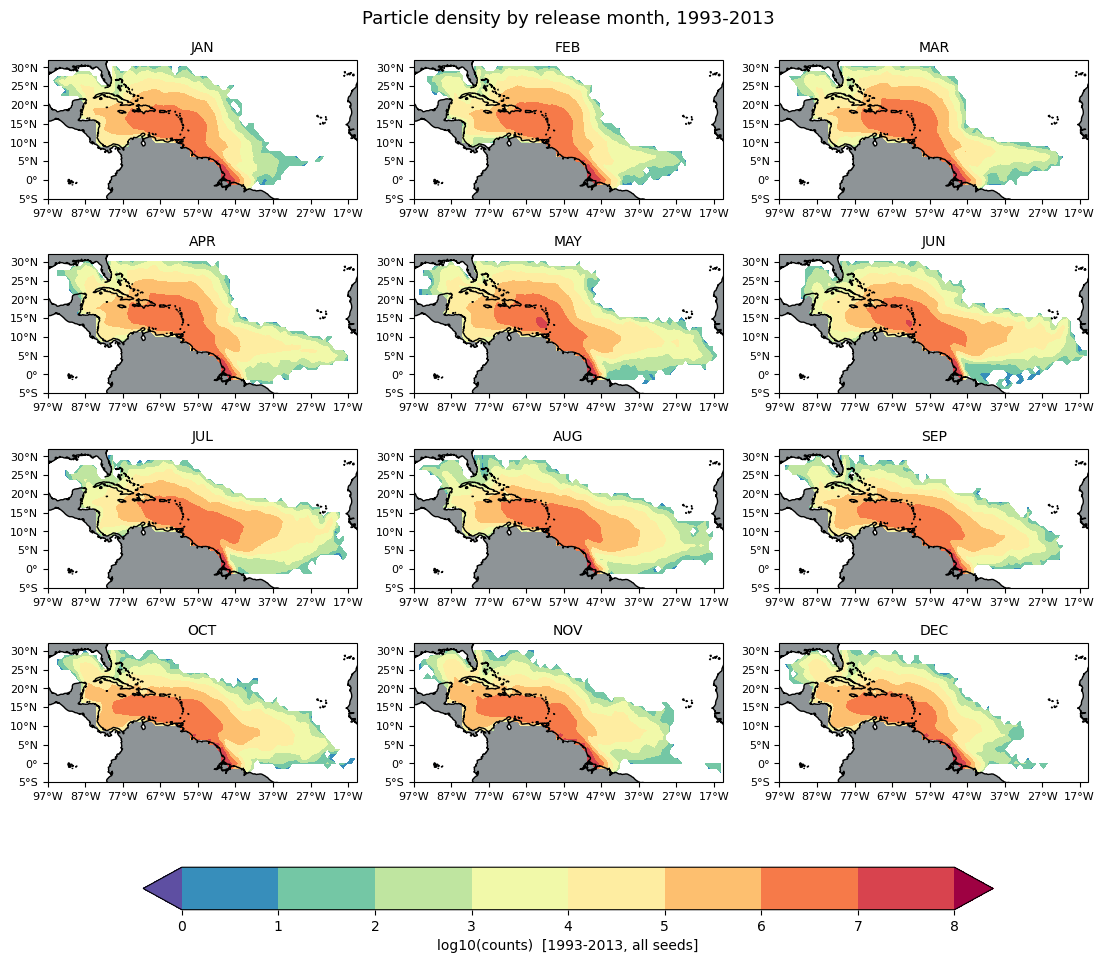

In [6]:
fig, ax = plt.subplots(4, 3, figsize=(12, 10), subplot_kw=dict(projection=proj))
ax = ax.ravel()
tot = hist_month.sum("obs")
vmax = float(np.log10(tot.where(tot > 0)).max())
levels = 10

for i in range(12):
    dd = tot.sel(start_month=i+1)
    pcm = np.log10(dd.where(dd > 0)).plot.contourf(
        x='lon', y='lat', ax=ax[i], transform=proj,
        add_colorbar=False, cmap='Spectral_r', levels=levels, extend='both')
    decorate(ax[i], dd, labs[i])

fig.subplots_adjust(left=0.05, right=0.95, bottom=0.08, top=0.93, wspace=0.05, hspace=0.4)
cbar = fig.colorbar(pcm, ax=ax, orientation='horizontal', fraction=0.05, pad=0.10)
cbar.ax.set_xlabel('log10(counts)  [1993-2013, all seeds]', fontsize=10)
fig.suptitle('Particle density by release month, 1993-2013', fontsize=13)
fig.savefig(os.path.join(fig_dir, "monthly_LPT_v3.png"), dpi=fig_dpi, bbox_inches="tight")
plt.show()

### Wet and dry seasons of the Amazon discharge

* OND -> dry season
* JFM -> transition
* AMJ -> wet season
* JAS -> transition

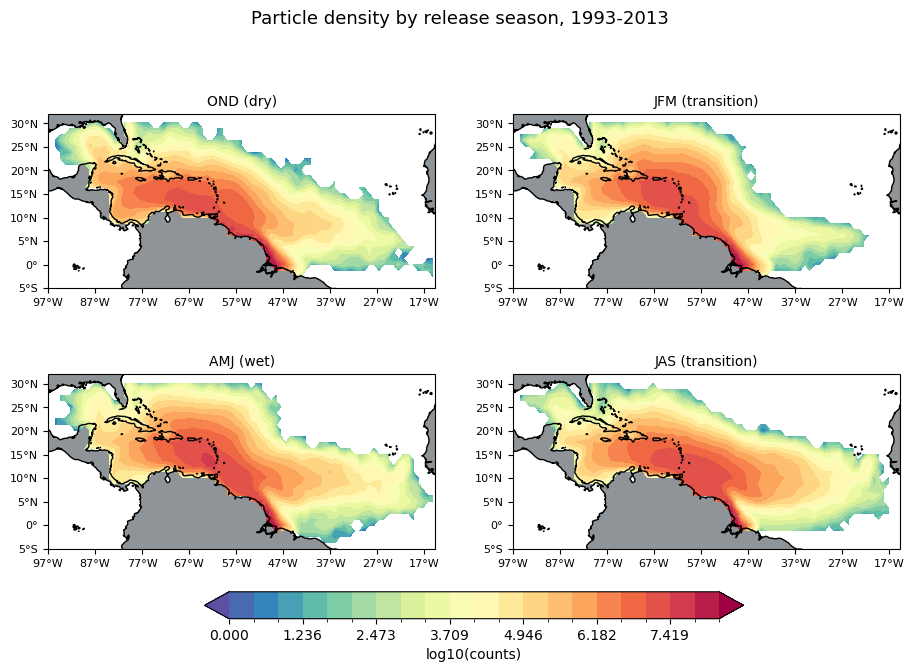

In [5]:
seasons = ['OND','JFM','AMJ','JAS']
titles  = {'OND':'OND (dry)', 'JFM':'JFM (transition)',
           'AMJ':'AMJ (wet)', 'JAS':'JAS (transition)'}

fig, ax = plt.subplots(2, 2, figsize=(11, 7), subplot_kw=dict(projection=proj))
ax = ax.ravel()
tot_s = hist_season.sum("obs")
vmax = float(np.log10(tot_s.where(tot_s > 0)).max())
levels = np.linspace(0, vmax, 21)
for i, s in enumerate(seasons):
    dd = tot_s.sel(start_season=s)
    pcm = np.log10(dd.where(dd > 0)).plot.contourf(
        x='lon', y='lat', ax=ax[i], transform=proj, add_colorbar=False,
        cmap='Spectral_r', levels=levels, extend='both')
    decorate(ax[i], dd, titles[s])
fig.subplots_adjust(wspace=0.20, hspace=0.25)
cbar = fig.colorbar(pcm, ax=ax, orientation='horizontal', fraction=0.05, pad=0.08)
cbar.ax.set_xlabel('log10(counts)', fontsize=10)
fig.suptitle('Particle density by release season, 1993-2013', fontsize=13)
fig.savefig(os.path.join(fig_dir, "season_wet_dry_LPT_v3.png"), dpi=fig_dpi, bbox_inches="tight")
plt.show()

## Probability density of the particle positions

positions entering this PDF: 9,353,640,093


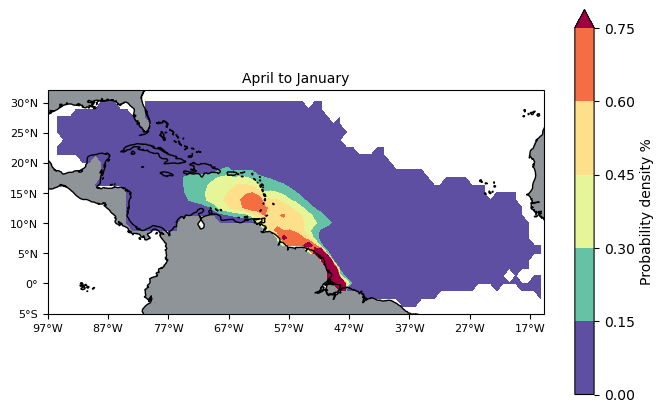

In [6]:
# April to January, as in the template notebook
counts = (hist_month.sel(start_month=slice(4, 12)).sum('start_month')
          + hist_month.sel(start_month=1)).sum('obs')
pp = counts/counts.sum()
pp = pp.where(pp != 0, np.nan)
print("positions entering this PDF:", f"{int(counts.sum()):,}")

fig, ax = plt.subplots(figsize=(8, 5), subplot_kw=dict(projection=proj))
(pp*100).rename('Probability density %').plot.contourf(
    x='lon', y='lat', ax=ax, transform=proj, robust=True, cmap='Spectral_r')
decorate(ax, counts, 'April to January')
fig.savefig(os.path.join(fig_dir, "pdf_apr_jan_LPT_v3.png"), dpi=fig_dpi, bbox_inches="tight")
plt.show()

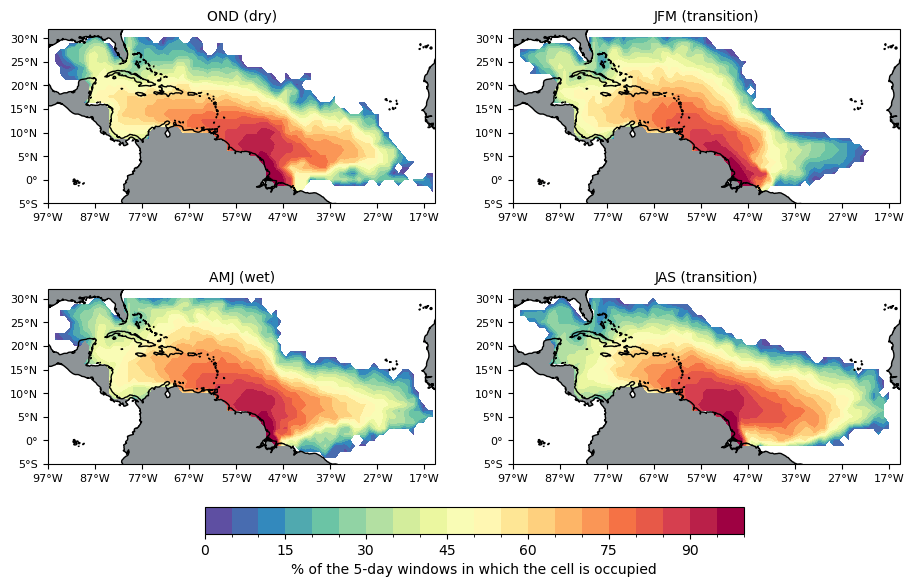

In [7]:
# occurrence: in how many of the 5-day obs bins is a cell occupied at all,
# per release season (%)
fig, ax = plt.subplots(2, 2, figsize=(11, 7), subplot_kw=dict(projection=proj))
ax = ax.ravel()
nobs = hist_season.sizes['obs']
for i, s in enumerate(seasons):
    occ = 100*(hist_season.sel(start_season=s) > 0).sum('obs')/nobs
    occ = occ.where(occ > 0)
    pcm = occ.rename('Occurrence %').plot.contourf(
        x='lon', y='lat', ax=ax[i], transform=proj, add_colorbar=False,
        cmap='Spectral_r', levels=np.linspace(0, 100, 21))
    decorate(ax[i], occ, titles[s])
fig.subplots_adjust(wspace=0.20, hspace=0.25)
cbar = fig.colorbar(pcm, ax=ax, orientation='horizontal', fraction=0.05, pad=0.08)
cbar.ax.set_xlabel('% of the 5-day windows in which the cell is occupied', fontsize=10)
fig.savefig(os.path.join(fig_dir, "occurrence_season_LPT_v3.png"), dpi=fig_dpi, bbox_inches="tight")
plt.show()

## Mean particle age

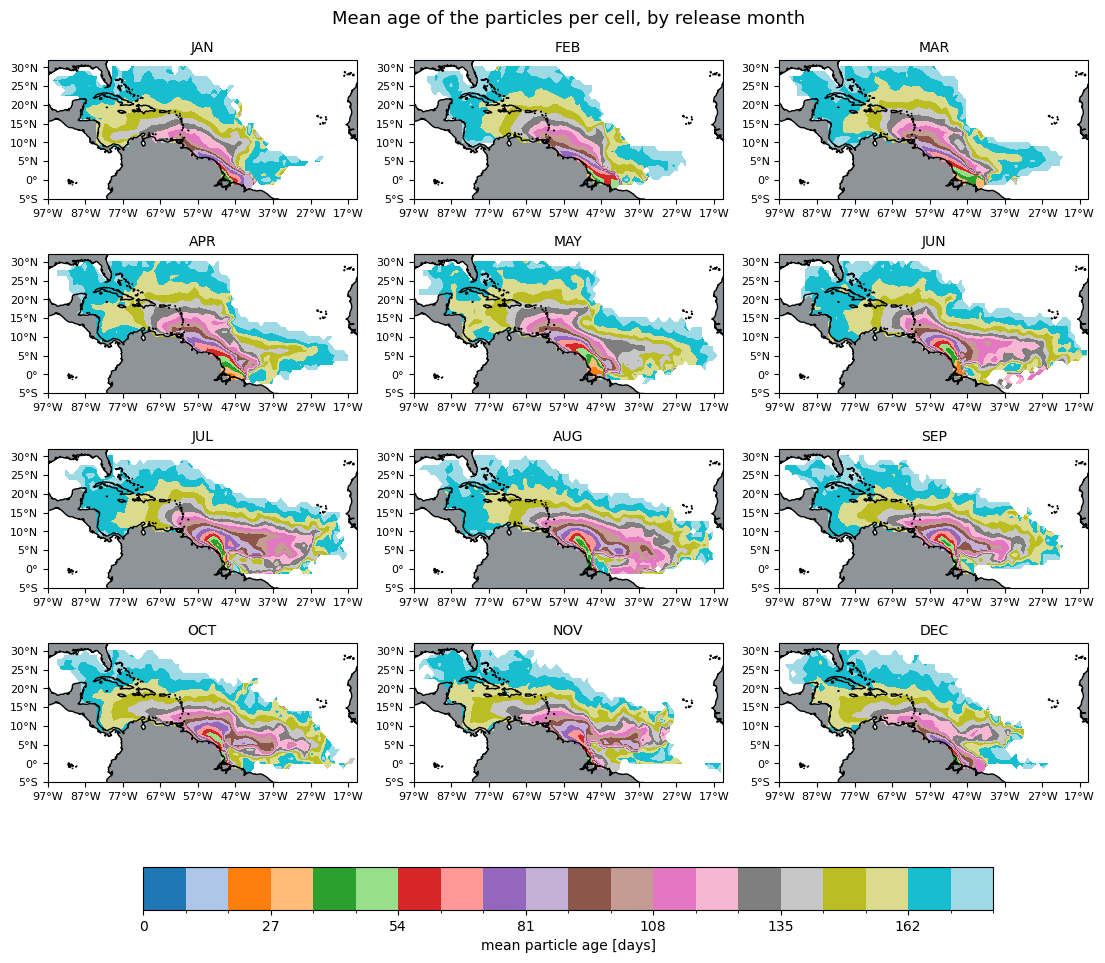

In [8]:
age = age_month.mean_age_days.astype("float64")
fig, ax = plt.subplots(4, 3, figsize=(12, 10), subplot_kw=dict(projection=proj))
ax = ax.ravel()
vmax = float(np.nanmax(age.values))
for i in range(12):
    dd = age.sel(start_month=i+1)
    pcm = dd.plot.contourf(x='lon', y='lat', ax=ax[i], transform=proj, cmap='tab20',
                           vmin=0, vmax=vmax, levels=21, add_colorbar=False)
    decorate(ax[i], dd, labs[i])
fig.subplots_adjust(left=0.05, right=0.95, bottom=0.08, top=0.93, wspace=0.05, hspace=0.4)
cbar = fig.colorbar(pcm, ax=ax, orientation='horizontal', fraction=0.05, pad=0.10)
cbar.ax.set_xlabel('mean particle age [days]', fontsize=10)
fig.suptitle('Mean age of the particles per cell, by release month', fontsize=13)
fig.savefig(os.path.join(fig_dir, "time_residence_LPT_v3.png"), dpi=fig_dpi, bbox_inches="tight")
plt.show()

## Spreading with time since release

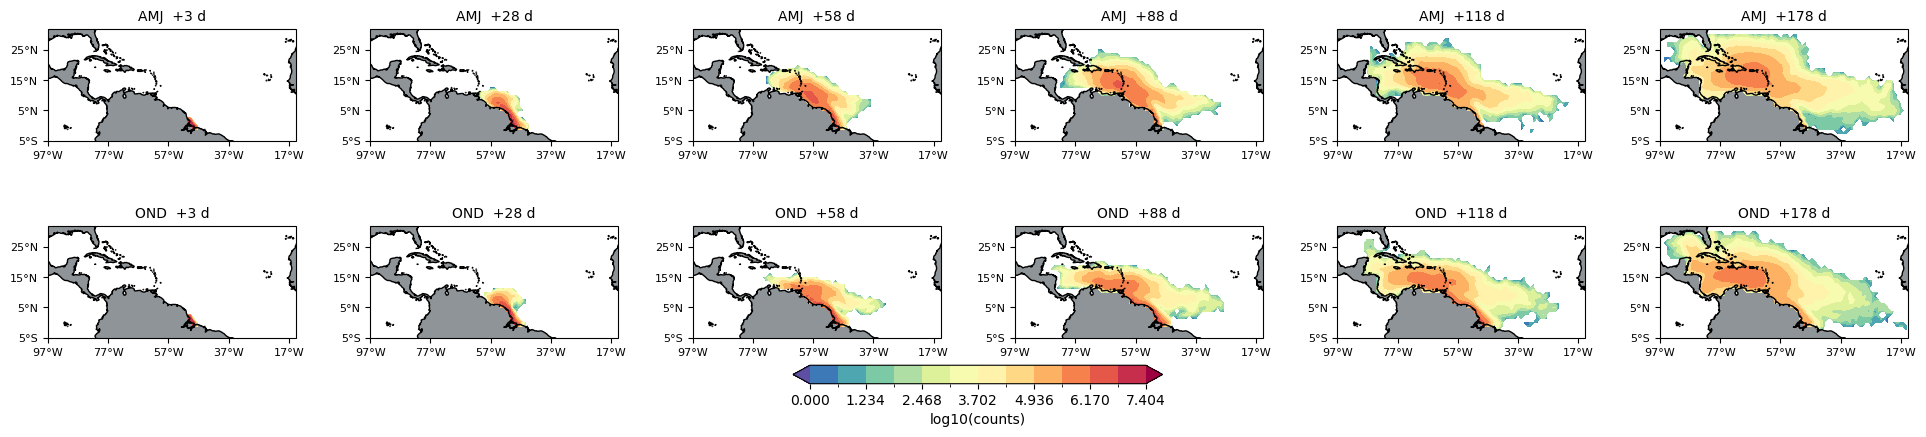

In [9]:
# how far the plume has got, 5-day windows, wet (AMJ) vs dry (OND) releases
sel_obs = [0, 5, 11, 17, 23, 35]     # ~2.6, 28, 58, 88, 118, 178 days
_sp = hist_season.isel(obs=sel_obs)
lev_sp = np.linspace(0, float(np.log10(_sp.where(_sp > 0)).max()), 13)
fig, ax = plt.subplots(2, len(sel_obs), figsize=(4*len(sel_obs), 6),
                       subplot_kw=dict(projection=proj))
for r, s in enumerate(['AMJ', 'OND']):
    for c, o in enumerate(sel_obs):
        dd = hist_season.sel(start_season=s).isel(obs=o)
        pcm = np.log10(dd.where(dd > 0)).plot.contourf(
            x='lon', y='lat', ax=ax[r, c], transform=proj, add_colorbar=False,
            cmap='Spectral_r', levels=lev_sp, extend='both')
        days = float(hist_season.days_since_release.isel(obs=o))
        decorate(ax[r, c], dd, f"{s}  +{days:.0f} d", dx=20, dy=10)
fig.subplots_adjust(wspace=0.30, hspace=-0.1)
cbar = fig.colorbar(pcm, ax=ax, orientation='horizontal', fraction=0.04, pad=0.06)
cbar.ax.set_xlabel('log10(counts)', fontsize=10)
fig.savefig(os.path.join(fig_dir, "spreading_time_LPT_v3.png"), dpi=fig_dpi, bbox_inches="tight")
plt.show()

## Interannual view of the monthly climatology

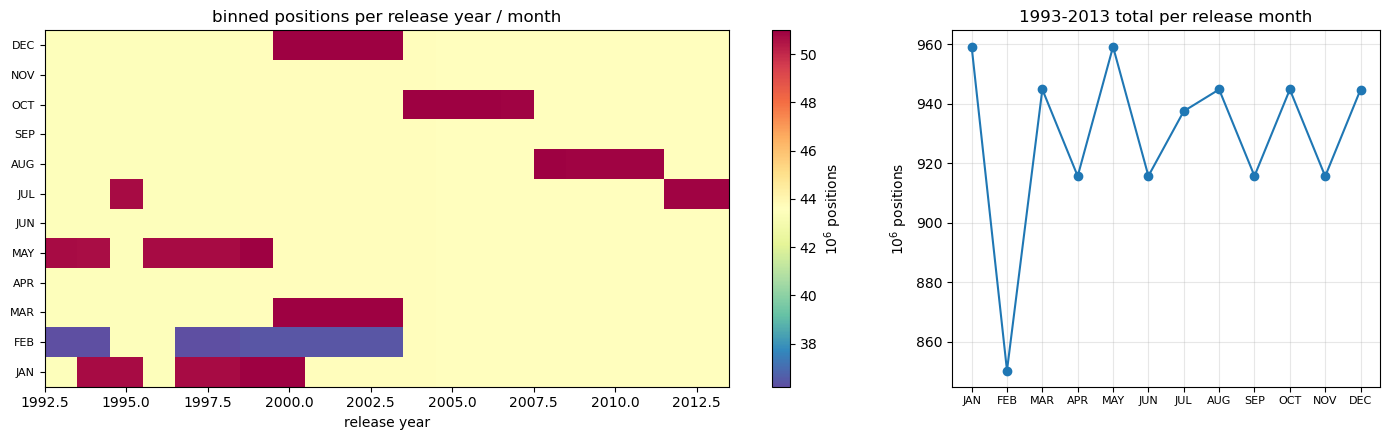

In [10]:
# number of binned positions per release year and month (a measure of how many
# particles survive in the domain for each release)
tab = hist_ym.sum(("obs", "lon", "lat"))
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5),
                       gridspec_kw=dict(width_ratios=[2, 1]))
(tab/1e6).plot.pcolormesh(x='start_year', y='start_month', ax=ax[0],
                          cmap='Spectral_r', cbar_kwargs=dict(label='10$^6$ positions'))
ax[0].set_yticks(np.arange(1, 13)); ax[0].set_yticklabels(labs, fontsize=8)
ax[0].set_title('binned positions per release year / month')
ax[0].set_xlabel('release year'); ax[0].set_ylabel('')

(tab.sum('start_year')/1e6).plot(ax=ax[1], marker='o')
ax[1].set_xticks(np.arange(1, 13)); ax[1].set_xticklabels(labs, fontsize=8)
ax[1].set_title('1993-2013 total per release month')
ax[1].set_xlabel(''); ax[1].set_ylabel('10$^6$ positions'); ax[1].grid(alpha=.3)
fig.tight_layout()
fig.savefig(os.path.join(fig_dir, "interannual_counts_v3.png"), dpi=fig_dpi, bbox_inches="tight")
plt.show()

## Blob analysis of the monthly PDFs

Same recipe as the template: smooth the monthly PDF, keep the cells above the
80th percentile of the non-zero density, and outline that blob.

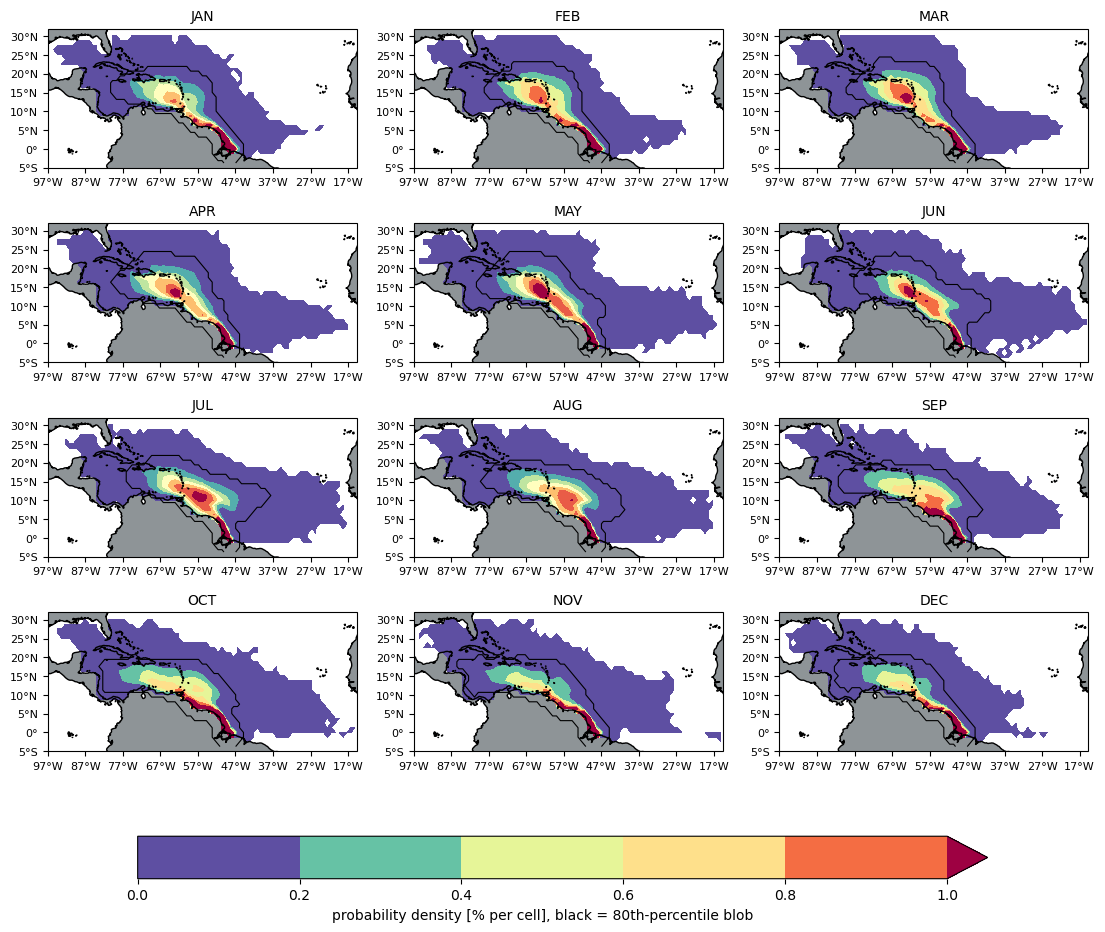

In [11]:
from scipy.ndimage import gaussian_filter

blobs_by_month = {}
for i in range(12):
    counts = hist_month.sel(start_month=i+1).sum("obs").fillna(0)
    pdf = counts/counts.sum()
    pdf_smooth = gaussian_filter(pdf.values.astype(float), sigma=1.0)
    thresh = np.percentile(pdf_smooth[pdf_smooth > 0], 80)
    blobs_by_month[i+1] = dict(mask=pdf_smooth >= thresh, pdf=pdf, thresh=thresh,
                               lon=pdf.lon.values, lat=pdf.lat.values)

fig, ax = plt.subplots(4, 3, figsize=(12, 10), subplot_kw=dict(projection=proj))
ax = ax.ravel()
for i in range(12):
    b = blobs_by_month[i+1]
    pdfm = b['pdf'].where(b['pdf'] > 0)
    pcm = (pdfm*100).plot.contourf(x='lon', y='lat', ax=ax[i], transform=proj,
                                   add_colorbar=False, cmap='Spectral_r', robust=True)
    ax[i].contour(b['lon'], b['lat'], b['mask'].T.astype(float), levels=[0.5],
                  colors='k', linewidths=0.8, transform=proj)
    decorate(ax[i], pdfm, labs[i])
fig.subplots_adjust(left=0.05, right=0.95, bottom=0.08, top=0.93, wspace=0.05, hspace=0.4)
cbar = fig.colorbar(pcm, ax=ax, orientation='horizontal', fraction=0.05, pad=0.10)
cbar.ax.set_xlabel('probability density [% per cell], black = 80th-percentile blob', fontsize=10)
fig.savefig(os.path.join(fig_dir, "pdf_blobs_month_v3.png"), dpi=fig_dpi, bbox_inches="tight")
plt.show()

In [12]:
print("figures written to", fig_dir)
for f in sorted(os.listdir(fig_dir)):
    print(f"  {f:40s} {os.path.getsize(os.path.join(fig_dir,f))/1e6:6.2f} MB")

figures written to /work/bk1450/b383184/Amazon/Mercator/notebooks/run_2/analysis/figures
  interannual_counts_v3.png                  0.22 MB
  monthly_LPT_v3.png                         1.14 MB
  occurrence_season_LPT_v3.png               0.45 MB
  pdf_apr_jan_LPT_v3.png                     0.18 MB
  pdf_blobs_month_v3.png                     1.03 MB
  season_wet_dry_LPT_v3.png                  0.48 MB
  spreading_time_LPT_v3.png                  0.66 MB
  time_residence_LPT_v3.png                  1.05 MB
  v2.mean_b_LPT_v3.png                       0.59 MB
  v2.mean_sal_LPT_v3.png                     0.51 MB
  v2.mean_sigma0_LPT_v3.png                  0.56 MB
  v2.mean_temp_LPT_v3.png                    0.54 MB
  v2.mean_z_LPT_v3.png                       0.51 MB
